# Synthetic experiments, version 2

Extends the first synthetic study to answer Reviewer 1 (comments 3, 4, 6, 17, 18) and Reviewer 2 (comments 4, 5).

**New in this version**
- **Holm-corrected class labels** (across the three classes) compared with unadjusted labels
- **Two block lengths** per persistence level (phi = 0.6: 12 and 24 months; phi = 0.9: 24 and 48 months) to see whether longer blocks restore the false-positive rate
- **Analytic ITA tests** (Sen 2017; Alashan 2020) alongside modified Mann-Kendall and the bootstrap ITA
- **New scenarios:** gradual linear trend over the whole series, and extreme-driven change (extra dry extremes injected into the second half)
- **ICSC stability study** versus sample size (numerical instability, untestable classes)

**Scenarios** (second half unless stated)
| Scenario | Change |
|---|---|
| `null` | none |
| `location` | whole distribution shifted by +d |
| `linear_trend` | linear trend over the whole 40 years (half-period shift = d/2) |
| `dry_tail` | values below -1 stretched downward |
| `wet_tail` | values above +1 stretched upward |
| `widen` / `narrow` | values multiplied by (1+d) / (1-d) |
| `extreme_dry` | each month has probability d of being pushed down by 2 SD (more dry extremes, middle unchanged) |

Run time at the defaults (`R = 200`, `B = 300`): roughly 20-30 minutes on one core. Lower `R` for a quick look.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import lfilter

R = 200; B = 300; N = 240; PHIS = (0.6, 0.9); LS = {0.6: (12, 24), 0.9: (24, 48)}   # first block length is the primary one
MIN_N = 10; SEED = 2026; ALPHA = 0.05; LEVELS = ['small', 'moderate', 'large']
SCEN = {'null': [0, 0, 0], 'location': [0.15, 0.30, 0.50], 'linear_trend': [0.30, 0.60, 1.00],
        'dry_tail': [0.5, 1.0, 1.5], 'wet_tail': [0.5, 1.0, 1.5], 'widen': [0.10, 0.20, 0.35],
        'narrow': [0.10, 0.20, 0.35], 'extreme_dry': [0.03, 0.06, 0.10]}
OUT = 'synthetic_v2_outputs'; os.makedirs(OUT, exist_ok=True)

## Comparators: modified Mann-Kendall (Hamed-Rao), Sen (2017), Alashan (2020)

In [2]:
def sen_slope(x):
    x = np.asarray(x, float); n = len(x)
    return np.median(np.concatenate([(x[k:] - x[:-k]) / k for k in range(1, n)]))

def mk_test(x, hr=True):
    """Mann-Kendall S, Z, p-value (two-sided) and Sen slope per time step. hr=True applies Hamed & Rao (1998)."""
    x = np.asarray(x, float); n = len(x)
    S = sum(np.sign(x[i + 1:] - x[i]).sum() for i in range(n - 1))
    _, cnt = np.unique(x, return_counts=True)
    var = (n * (n - 1) * (2 * n + 5) - np.sum(cnt * (cnt - 1) * (2 * cnt + 5))) / 18.0
    beta = sen_slope(x); f = 1.0
    if hr:
        r = stats.rankdata(x - beta * np.arange(n)); r = r - r.mean(); den = (r * r).sum()
        lim = stats.norm.ppf(0.975) / np.sqrt(n); sni = 0.0
        for k in range(1, n - 1):
            a = (r[:-k] * r[k:]).sum() / den
            if abs(a) > lim: sni += (n - k) * (n - k - 1) * (n - k - 2) * a
        f = 1 + 2.0 / (n * (n - 1) * (n - 2)) * sni
        f = f if f > 0 else 1.0
    z = 0.0 if S == 0 else (S - np.sign(S)) / np.sqrt(var * f)
    return dict(S=S, Z=z, p=2 * (1 - stats.norm.cdf(abs(z))), sen=beta, vcf=f)

def direction(p, est, alpha=0.05):
    return '0' if not (p < alpha) else ('+' if est > 0 else '-')

In [3]:
def sen2017_sig(x1, x2, alpha=0.05):
    n = len(x1) + len(x2); s = 2 * (x2.mean() - x1.mean()) / n
    rho = np.corrcoef(np.sort(x1), np.sort(x2))[0, 1]
    sd = np.sqrt(8.0 * np.var(np.concatenate([x1, x2]), ddof=1) * max(1 - rho, 1e-12)) / n
    return abs(s / sd) > stats.norm.ppf(1 - alpha / 2)
def alashan2020_sig(x1, x2, alpha=0.05):
    a, b = np.sort(x1), np.sort(x2); n = len(a) + len(b); s = 2 * (b.mean() - a.mean()) / n
    s1, s2 = a.std(ddof=1), b.std(ddof=1); rho = np.corrcoef(a, b)[0, 1]
    sd = (2.0 / n) * np.sqrt(max(s1 ** 2 + s2 ** 2 - 2 * rho * s1 * s2, 1e-12))
    return abs(s / sd) > stats.norm.ppf(1 - alpha / 2)

## SH-ITA statistics, bootstrap, Holm correction

In [4]:
def slope(x, y):
    return np.nan if len(x) < 2 or np.ptp(x) == 0 else np.polyfit(x, y, 1)[0]
def ita_stats(x, y):
    xs, ys = np.sort(x), np.sort(y)
    cls = np.where(xs <= -1, 0, np.where(xs >= 1, 2, 1)); r = {}
    for k, nm in enumerate(['low', 'med', 'high']):
        m = cls == k; r['n_' + nm] = int(m.sum()); r['slope_' + nm] = slope(xs[m], ys[m])
        r['D_' + nm] = (ys[m] - xs[m]).mean() if m.any() else np.nan
    r['IISC'] = (ys.mean() - xs.mean()) / np.abs(xs).mean()
    sl, sh = r['slope_low'], r['slope_high']
    r['ICSC'] = (sh - sl) / abs(sh + sl) if np.isfinite(sl) and np.isfinite(sh) and abs(sh + sl) > 0 else np.nan
    r['A'] = r['D_high'] - r['D_low']
    return r
def cbb(a, L, rng):
    n = len(a); nb = int(np.ceil(n / L))
    return a[(rng.integers(0, n, nb)[:, None] + np.arange(L)).ravel()[:n] % n]
KEYS = ['D_low', 'D_med', 'D_high', 'IISC', 'ICSC', 'A']
def boot_p(v):
    v = v[np.isfinite(v)]
    return np.nan if len(v) < 100 else max(2 * min((v <= 0).mean(), (v >= 0).mean()), 1.0 / (len(v) + 1))
def holm(pvals):
    p = np.array(pvals, float); out = np.full_like(p, np.nan); ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]; m = len(order); run = 0.0
    for rank, i in enumerate(order): run = max(run, min(1.0, (m - rank) * p[i])); out[i] = run
    return out
def lab(D, p):
    return '-' if not np.isfinite(p) else ('No' if p >= ALPHA else ('Yes(+)' if D > 0 else 'Yes(-)'))

def analyse_sim(x, y, L, rng):
    base = ita_stats(x, y); bt = {k: [] for k in KEYS}
    for _ in range(B):
        r = ita_stats(cbb(x, L, rng), cbb(y, L, rng))
        for k in KEYS: bt[k].append(r[k])
    bt = {k: np.array(v, float) for k, v in bt.items()}; names = ['low', 'med', 'high']
    p_raw = [boot_p(bt['D_' + nm]) if base['n_' + nm] >= MIN_N else np.nan for nm in names]; p_adj = holm(p_raw)
    out = {}
    for i, nm in enumerate(names):
        out[nm + '_unadj'] = lab(base['D_' + nm], p_raw[i]); out[nm + '_holm'] = lab(base['D_' + nm], p_adj[i])
    pI, pA, pC = boot_p(bt['IISC']), boot_p(bt['A']), boot_p(bt['ICSC'])
    out.update(ita_sig=bool(pI < ALPHA), ita_dir='+' if base['IISC'] > 0 else '-', A_clear=bool(pA < ALPHA), ICSC_clear=bool(pC < ALPHA))
    return out

## Simulation

In [5]:
def ar1(n, phi, rng, burn=200):
    return lfilter([np.sqrt(1 - phi ** 2)], [1, -phi], rng.standard_normal(n + burn))[burn:]
def make_series(scen, d, phi, rng):
    s = ar1(2 * N, phi, rng)
    if scen == 'linear_trend': s = s + d * (np.arange(2 * N) / (2 * N - 1) - 0.5)
    x, y = s[:N], s[N:].copy()
    if scen == 'location': y = y + d
    elif scen == 'dry_tail': y = y - d * np.maximum(0, -1 - y)
    elif scen == 'wet_tail': y = y + d * np.maximum(0, y - 1)
    elif scen == 'widen': y = y * (1 + d)
    elif scen == 'narrow': y = y * (1 - d)
    elif scen == 'extreme_dry': y = y - 2.0 * (rng.random(N) < d)
    return x, y
def diagnosis(scen, r, key):
    """Did the class labels (key = 'holm' or 'unadj') give the correct tail-specific diagnosis? For null: any label = false positive."""
    lo, me, hi = r['low_' + key], r['med_' + key], r['high_' + key]
    if scen == 'null': return any(v.startswith('Yes') for v in (lo, me, hi))
    if scen in ('location', 'linear_trend'): return r['ita_sig'] and r['ita_dir'] == '+'
    if scen in ('dry_tail', 'extreme_dry'): return lo == 'Yes(-)'
    if scen == 'wet_tail': return hi == 'Yes(+)'
    if scen == 'widen': return lo == 'Yes(-)' and hi == 'Yes(+)'
    if scen == 'narrow': return lo == 'Yes(+)' and hi == 'Yes(-)'

def run_conditions(R=R, phis=PHIS, scens=SCEN, verbose=True):
    rows = []
    for phi in phis:
        for si, (scen, ds) in enumerate(scens.items()):
            for li, (lev, d) in enumerate(zip(LEVELS, ds)):
                if scen == 'null' and li > 0: continue
                rng = np.random.default_rng([SEED, int(phi * 100), si, li])
                for rep in range(R):
                    x, y = make_series(scen, d, phi, rng)
                    m = mk_test(np.concatenate([x, y]), hr=True)
                    base = dict(phi=phi, scenario=scen, level=('none' if scen == 'null' else lev), d=d,
                                MMK=m['p'] < ALPHA, Sen2017=sen2017_sig(x, y), Alashan2020=alashan2020_sig(x, y))
                    for L in LS[phi]:
                        r = analyse_sim(x, y, L, rng)
                        rows.append(dict(base, L=L, ITA_bootstrap=r['ita_sig'], class_any_unadj=any(r[k + '_unadj'].startswith('Yes') for k in ('low', 'med', 'high')),
                                         class_any_holm=any(r[k + '_holm'].startswith('Yes') for k in ('low', 'med', 'high')),
                                         diag_unadj=diagnosis(scen, r, 'unadj'), diag_holm=diagnosis(scen, r, 'holm'),
                                         A_clear=r['A_clear'], ICSC_clear=r['ICSC_clear']))
                if verbose: print('done', phi, scen, lev, flush=True)
    return pd.DataFrame(rows)

In [6]:
SIM = run_conditions()

done 0.6 null small
done 0.6 location small
done 0.6 location moderate
done 0.6 location large
done 0.6 linear_trend small
done 0.6 linear_trend moderate
done 0.6 linear_trend large
done 0.6 dry_tail small
done 0.6 dry_tail moderate
done 0.6 dry_tail large
done 0.6 wet_tail small
done 0.6 wet_tail moderate
done 0.6 wet_tail large
done 0.6 widen small
done 0.6 widen moderate
done 0.6 widen large
done 0.6 narrow small
done 0.6 narrow moderate
done 0.6 narrow large
done 0.6 extreme_dry small
done 0.6 extreme_dry moderate
done 0.6 extreme_dry large
done 0.9 null small
done 0.9 location small
done 0.9 location moderate
done 0.9 location large
done 0.9 linear_trend small
done 0.9 linear_trend moderate
done 0.9 linear_trend large
done 0.9 dry_tail small
done 0.9 dry_tail moderate
done 0.9 dry_tail large
done 0.9 wet_tail small
done 0.9 wet_tail moderate
done 0.9 wet_tail large
done 0.9 widen small
done 0.9 widen moderate
done 0.9 widen large
done 0.9 narrow small
done 0.9 narrow moderate
done

## False-positive rates (nominal 5%) and power

In [7]:
cols = ['MMK', 'Sen2017', 'Alashan2020', 'ITA_bootstrap', 'class_any_unadj', 'class_any_holm', 'A_clear', 'ICSC_clear']
NULL = SIM[SIM.scenario == 'null'].groupby(['phi', 'L'])[cols].mean().round(3)
NULL['n_datasets'] = SIM[SIM.scenario == 'null'].groupby(['phi', 'L']).size()
print('FALSE-POSITIVE RATES under no change (nominal 0.05). class_any_* = at least one of the 3 class labels is Yes.')
print(NULL.to_string())
pcols = ['MMK', 'Alashan2020', 'ITA_bootstrap', 'diag_unadj', 'diag_holm', 'A_clear', 'ICSC_clear']
order = {l: i for i, l in enumerate(LEVELS)}
POW = SIM[SIM.scenario != 'null'].groupby(['phi', 'L', 'scenario', 'level'])[pcols].mean().round(2).reset_index()
POW['o'] = POW.level.map(order); POW = POW.sort_values(['phi', 'L', 'scenario', 'o']).drop(columns='o')
print('\nDETECTION RATES (diag_* = correct tail-specific diagnosis)')
print(POW.to_string(index=False))

FALSE-POSITIVE RATES under no change (nominal 0.05). class_any_* = at least one of the 3 class labels is Yes.
          MMK  Sen2017  Alashan2020  ITA_bootstrap  class_any_unadj  class_any_holm  A_clear  ICSC_clear  n_datasets
phi L                                                                                                               
0.6 12  0.175    0.285         0.18          0.095            0.270           0.140    0.110       0.035         200
    24  0.175    0.285         0.18          0.100            0.315           0.140    0.140       0.055         200
0.9 24  0.240    0.465         0.28          0.140            0.285           0.175    0.100       0.030         200
    48  0.240    0.465         0.28          0.140            0.290           0.205    0.085       0.040         200

DETECTION RATES (diag_* = correct tail-specific diagnosis)
 phi  L     scenario    level  MMK  Alashan2020  ITA_bootstrap  diag_unadj  diag_holm  A_clear  ICSC_clear
 0.6 12     dry_tail 

## ICSC numerical stability versus sample size (null, phi = 0.6)

In [8]:
rng = np.random.default_rng(SEED); rows = []
for nh in (50, 100, 240, 480):
    nlow_bad = inst = ext = tot = 0; sl_abs = []
    for _ in range(3000):
        s = ar1(2 * nh, 0.6, rng); r = ita_stats(s[:nh], s[nh:]); tot += 1
        if r['n_low'] < MIN_N or r['n_high'] < MIN_N: nlow_bad += 1; continue
        sl_abs += [abs(r['slope_low']), abs(r['slope_high'])]
        if not np.isfinite(r['ICSC']): continue
        inst += abs(r['ICSC']) > 0.9; ext += max(abs(r['slope_low']), abs(r['slope_high'])) > 3
    ok = tot - nlow_bad
    rows.append(dict(months_per_half=nh, untestable_share=round(nlow_bad / tot, 3), abs_ICSC_gt_0_9=round(inst / max(ok, 1), 3),
                     max_class_slope_gt_3=round(ext / max(ok, 1), 3), median_abs_class_slope=round(float(np.median(sl_abs)), 2)))
STAB = pd.DataFrame(rows); print('Under NO change: how often is ICSC pinned near +/-1, or slopes extreme?'); STAB

Under NO change: how often is ICSC pinned near +/-1, or slopes extreme?


,months_per_half,untestable_share,abs_ICSC_gt_0_9,max_class_slope_gt_3,median_abs_class_slope
0,50,0.959,0.0,0.000,0.96
1,100,0.259,0.0,0.007,0.94
2,240,0.000,0.0,0.000,0.97
3,480,0.000,0.0,0.000,0.98


## Calibrating the testing threshold under no change

The false-positive table shows the bootstrap p-values are too liberal for serially dependent series. This cell finds the **significance level that would give a 5% false-positive rate** under no change (the 5th percentile of the null p-values), separately for each persistence level. Use it as an *effective alpha* for the labels, IISC and A.

The calibration is run at four persistence levels. The levels used in the paper are those matching the real series: AR(1) = 0.75 for 3-month and 0.95 for 12-month indices.

In [9]:
def null_pvalues(phi, L, Rc=400):
    rng = np.random.default_rng([SEED, 777, int(phi * 100)]); out = []
    for _ in range(Rc):
        s = ar1(2 * N, phi, rng); x, y = s[:N], s[N:]; base = ita_stats(x, y); bt = {k: [] for k in KEYS}
        for _ in range(B):
            r = ita_stats(cbb(x, L, rng), cbb(y, L, rng))
            for k in KEYS: bt[k].append(r[k])
        bt = {k: np.array(v, float) for k, v in bt.items()}
        p_raw = [boot_p(bt['D_' + nm]) if base['n_' + nm] >= MIN_N else np.nan for nm in ('low', 'med', 'high')]; p_adj = holm(p_raw)
        out.append(dict(min_class_holm=np.nanmin(p_adj) if np.isfinite(p_adj).any() else 1.0, p_IISC=boot_p(bt['IISC']),
                        p_A=boot_p(bt['A']), p_ICSC=boot_p(bt['ICSC'])))
    return pd.DataFrame(out)
# 0.6 and 0.9 match the simulated scenarios; 0.75 and 0.95 match the real series (lag-1 autocorrelation 0.59-0.86 at 3 months, 0.94-0.98 at 12 months)
CAL_PHIS = {0.6: 12, 0.75: 12, 0.9: 24, 0.95: 24}
CAL = {phi: null_pvalues(phi, L) for phi, L in CAL_PHIS.items()}
CALIB = pd.DataFrame({phi: df.quantile(0.05) for phi, df in CAL.items()}).T.round(3)
CALIB.index.name = 'phi'
print('Effective alpha giving a 5% false-positive rate under no change (nominal alpha = 0.05):'); CALIB

Effective alpha giving a 5% false-positive rate under no change (nominal alpha = 0.05):


,min_class_holm,p_IISC,p_A,p_ICSC
phi,,,,
0.60,0.020,0.027,0.027,0.046
0.75,0.010,0.020,0.026,0.047
0.90,0.010,0.007,0.007,0.053
0.95,0.007,0.003,0.005,0.094


## Figures

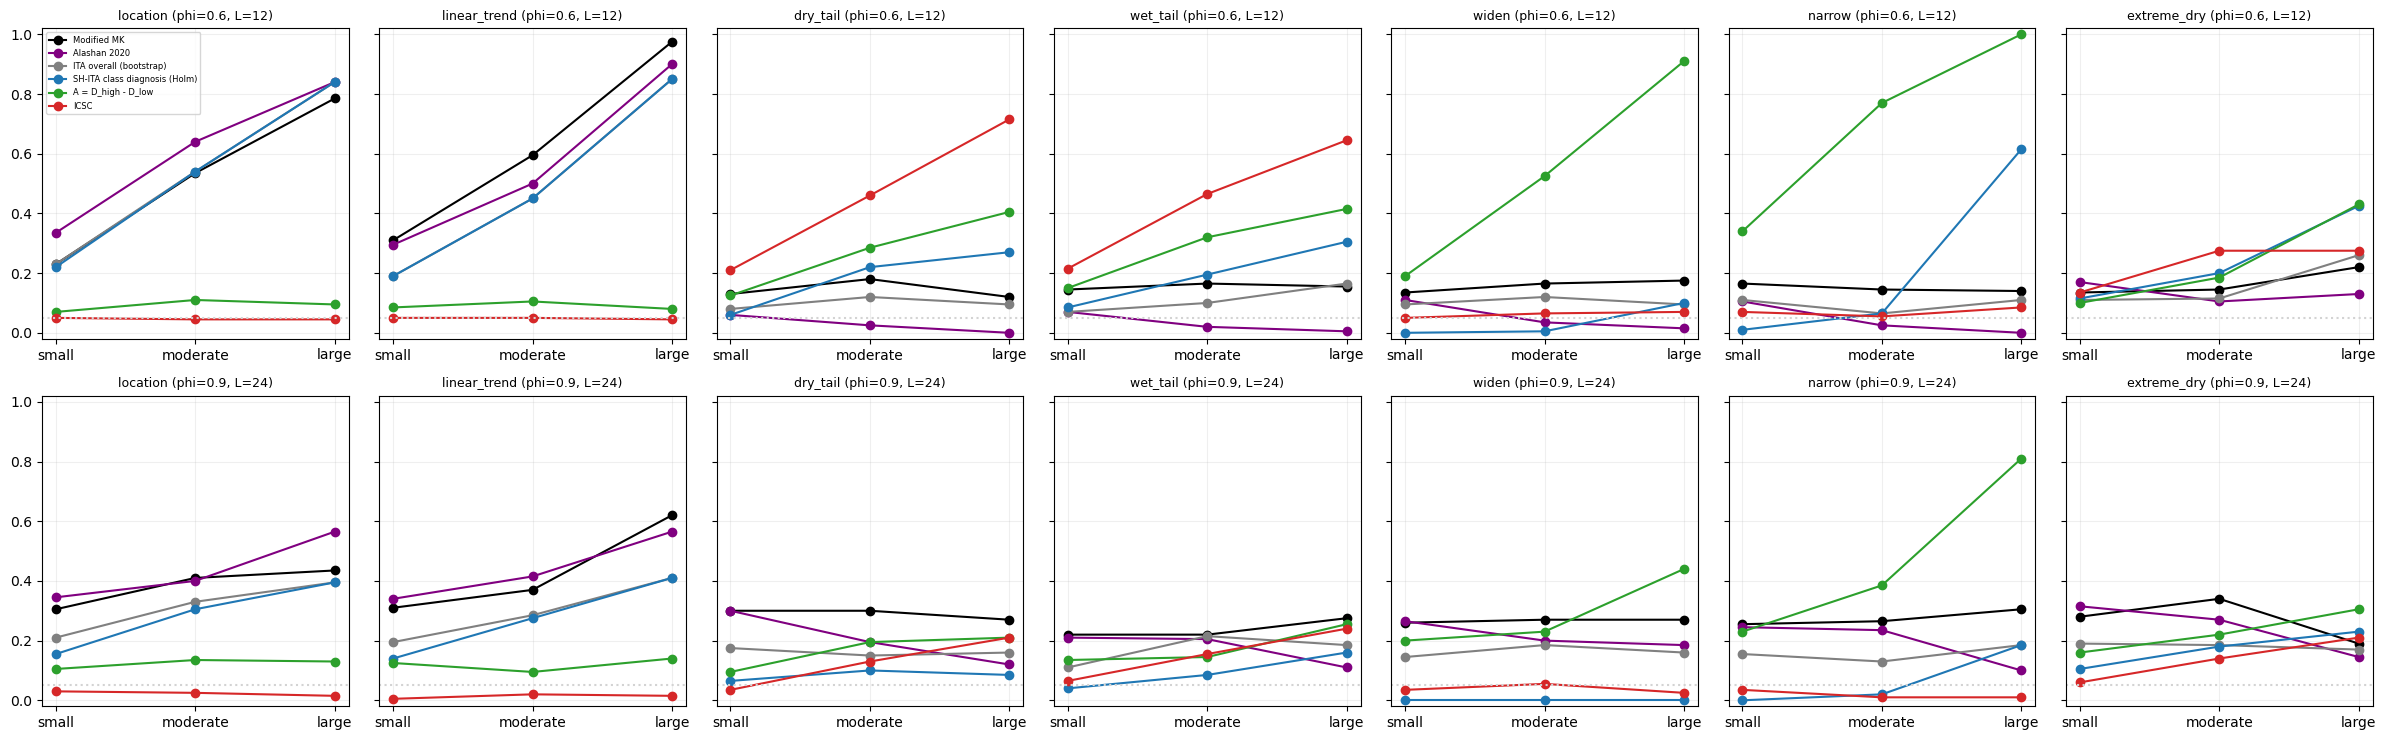

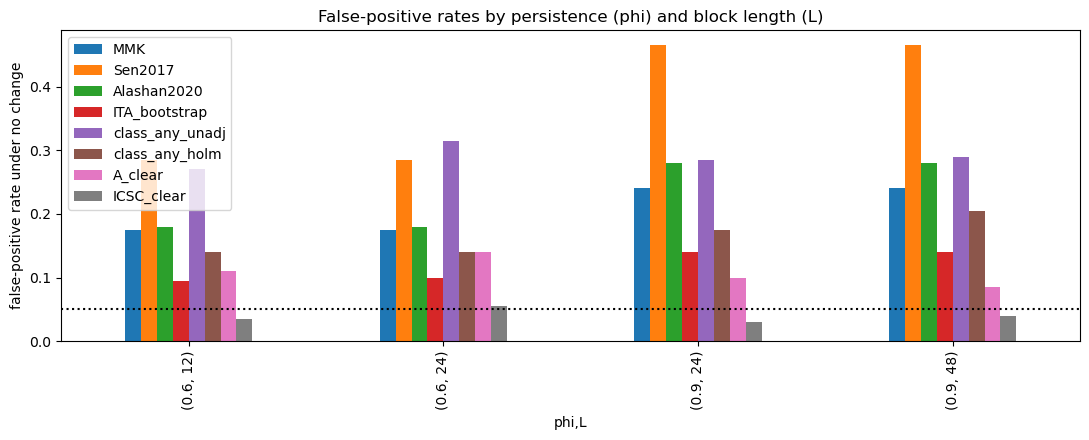

In [10]:
prim = {p: LS[p][0] for p in PHIS}; sc_list = [s for s in SCEN if s != 'null']
styles = {'MMK': ('k', 'Modified MK'), 'Alashan2020': ('purple', 'Alashan 2020'), 'ITA_bootstrap': ('gray', 'ITA overall (bootstrap)'),
          'diag_holm': ('tab:blue', 'SH-ITA class diagnosis (Holm)'), 'A_clear': ('tab:green', 'A = D_high - D_low'), 'ICSC_clear': ('tab:red', 'ICSC')}
fig, axes = plt.subplots(len(PHIS), len(sc_list), figsize=(24, 7.5), sharey=True)
for i, phi in enumerate(PHIS):
    for j, scen in enumerate(sc_list):
        ax = axes[i, j]; sub = SIM[(SIM.phi == phi) & (SIM.L == prim[phi]) & (SIM.scenario == scen)].groupby('level')[list(styles)].mean().reindex(LEVELS)
        for k, (c, lab_) in styles.items(): ax.plot(LEVELS, sub[k], 'o-', color=c, label=lab_)
        ax.axhline(0.05, color='lightgray', ls=':'); ax.set_ylim(-0.02, 1.02); ax.set_title(f'{scen} (phi={phi}, L={prim[phi]})', fontsize=9); ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=6); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'synthetic_v2_power.png'), dpi=200); plt.show()
fig, ax = plt.subplots(figsize=(11, 4.5)); NULL[cols].plot.bar(ax=ax); ax.axhline(0.05, color='k', ls=':'); ax.set_ylabel('false-positive rate under no change')
ax.set_title('False-positive rates by persistence (phi) and block length (L)'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'synthetic_v2_false_positives.png'), dpi=200); plt.show()

## Export

In [11]:
with pd.ExcelWriter(os.path.join(OUT, 'synthetic_v2_results.xlsx'), engine='openpyxl') as w:
    NULL.reset_index().to_excel(w, sheet_name='False-positive rates', index=False)
    POW.to_excel(w, sheet_name='Detection rates', index=False)
    STAB.to_excel(w, sheet_name='ICSC stability', index=False)
    CALIB.reset_index().to_excel(w, sheet_name='Effective alpha', index=False)
print('saved to', OUT)

saved to synthetic_v2_outputs
